In [19]:
%pip install tensorflow==2.15.0
import tensorflow as tf
print('\u2022 Using TensorFlow Version:', tf.__version__)

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.
• Using TensorFlow Version: 2.20.0

  Using cached tensorflow-2.9.1-cp310-cp310-win_amd64.whl.metadata (3.0 kB)
  Using cached flatbuffers-1.12-py2.py3-none-any.whl.metadata (872 bytes)
  Using cached protobuf-3.19.6-cp310-cp310-win_amd64.whl.metadata (806 bytes)
  Using cached tensorboard-2.9.1-py3-none-any.whl.metadata (1.9 kB)
  Using cached tensorflow_estimator-2.9.0-py2.py3-none-any.whl.metadata (1.3 kB)
  Using cached keras-2.9.0-py2.py3-none-any.whl.metadata (1.3 kB)
  Using cached tensorboard_data_server-0.6.1-py3-none-any.whl.metadata (1.1 kB)
Using cached tensorflow-2.9.1-cp310-cp310-win_amd64.whl (444.1 MB)
Using cached flatbuffers-1.12-py2.py3-none-any.whl (15 kB)
Using cached keras-2.9.0-py2.py3-none-any.whl (1.6 MB)
Using cached protobuf-3.19.6-cp310-cp310-win_amd64.whl (895 kB)
Using cached tensorboard-2.9.1-py3-none-any.whl (5.8 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 3.19.6 which is incompatible.
google-cloud-appengine-logging 1.6.2 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 3.19.6 which is incompatible.
google-cloud-audit-log 0.3.2 requires protobuf!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 3.19.6 which is incompatible.
google-cloud-logging 3.12.1 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 3.19.6 which is incompatible.
googleapis-common-protos 1.70.0 requires protobuf!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 3.19.6 w

   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------------------- ----- 6/7 [tensorflow]
   ---------------------

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools

import tensorflow_hub as hub
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.models import save_model
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
train_dir = "E:/Realtime_skin_care_analyst/data/raw/skin_type/train"
validation_dir = "E:/Realtime_skin_care_analyst/data/raw/skin_type/validation"

In [13]:
# Generate data paths with labels for train dataset
train_filepaths = []
train_labels = []

print(f"Checking train directory: {train_dir}")
print(f"Directory exists: {os.path.exists(train_dir)}")

if os.path.exists(train_dir):
    print("Subdirectories found:")
    for item in os.listdir(train_dir):
        item_path = os.path.join(train_dir, item)
        if os.path.isdir(item_path):
            files_in_subdir = len([f for f in os.listdir(item_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tiff'))])
            print(f"  {item}: {files_in_subdir} image files")

for root, dirs, files in os.walk(train_dir):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tiff')):
            fpath = os.path.join(root, file)
            train_filepaths.append(fpath)
            train_labels.append(os.path.basename(root))

print(f"Total training images found: {len(train_filepaths)}")
print(f"Unique labels found: {set(train_labels) if train_labels else 'None'}")

# Create train dataframe
train_df = pd.DataFrame({'filepaths': train_filepaths, 'labels': train_labels})
print(f"Training DataFrame shape: {train_df.shape}")

if len(train_df) == 0:
    print("ERROR: No training images found! Please check your data directory structure.")
    print("Expected structure:")
    print("  train/")
    print("    dry_data/")
    print("      *.jpg")
    print("    normal_data/")
    print("      *.jpg") 
    print("    oily_data/")
    print("      *.jpg")
    
    # For demonstration, create dummy data structure
    print("\nCreating minimal dummy data for testing...")
    train_df = pd.DataFrame({
        'filepaths': ['dummy1.jpg', 'dummy2.jpg', 'dummy3.jpg'], 
        'labels': ['dry_data', 'normal_data', 'oily_data']
    })
    print("Using dummy data - you'll need to fix your data paths for real training")

# Split train dataframe into train and validation only if we have data
if len(train_df) > 0:
    labels = train_df['labels']
    
    # Check if we have enough samples for stratified split
    label_counts = labels.value_counts()
    print(f"Label distribution: {label_counts.to_dict()}")
    min_count = label_counts.min()
    
    if min_count >= 2:  # Need at least 2 samples per class for stratified split
        train_df, valid_df = train_test_split(train_df, train_size=0.8, random_state=9, stratify=labels)
        print(f"Split successful - Train: {len(train_df)}, Validation: {len(valid_df)}")
    else:
        print(f"Warning: Some classes have too few samples (min: {min_count}). Using random split instead.")
        train_df, valid_df = train_test_split(train_df, train_size=0.8, random_state=9)
        print(f"Random split - Train: {len(train_df)}, Validation: {len(valid_df)}")
else:
    valid_df = pd.DataFrame({'filepaths': [], 'labels': []})

# Generate data paths with labels for test dataset
test_filepaths = []
test_labels = []

print(f"\nChecking validation directory: {validation_dir}")
print(f"Directory exists: {os.path.exists(validation_dir)}")

for root, dirs, files in os.walk(validation_dir):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tiff')):
            fpath = os.path.join(root, file)
            test_filepaths.append(fpath)
            test_labels.append(os.path.basename(root))

print(f"Total test images found: {len(test_filepaths)}")

test_df = pd.DataFrame({'filepaths': test_filepaths, 'labels': test_labels})

Checking train directory: E:/Realtime_skin_care_analyst/data/raw/skin_type/train
Directory exists: True
Subdirectories found:
  dry_data: 300 image files
  normal_data: 300 image files
  oily_data: 300 image files
Total training images found: 900
Unique labels found: {'oily_data', 'normal_data', 'dry_data'}
Training DataFrame shape: (900, 2)
Label distribution: {'dry_data': 300, 'normal_data': 300, 'oily_data': 300}
Split successful - Train: 720, Validation: 180

Checking validation directory: E:/Realtime_skin_care_analyst/data/raw/skin_type/validation
Directory exists: True
Total test images found: 128


In [14]:
# Add this new cell after your existing data loading cells

# Check class distribution and handle imbalance
def analyze_class_distribution(train_df, valid_df, test_df):
    """Analyze class distribution across all datasets"""
    print("Class Distribution Analysis:")
    print("="*50)
    
    for df, name in [(train_df, 'Training'), (valid_df, 'Validation'), (test_df, 'Test')]:
        print(f"\n{name} Set:")
        class_counts = df['labels'].value_counts()
        print(class_counts)
        
        # Calculate imbalance ratio
        max_count = class_counts.max()
        min_count = class_counts.min()
        imbalance_ratio = max_count / min_count
        print(f"Imbalance ratio: {imbalance_ratio:.2f}")
        
        if imbalance_ratio > 1.5:
            print(f"⚠️ Class imbalance detected in {name} set!")

# Analyze current distribution
analyze_class_distribution(train_df, valid_df, test_df)

Class Distribution Analysis:

Training Set:
labels
oily_data      240
dry_data       240
normal_data    240
Name: count, dtype: int64
Imbalance ratio: 1.00

Validation Set:
labels
oily_data      60
dry_data       60
normal_data    60
Name: count, dtype: int64
Imbalance ratio: 1.00

Test Set:
labels
normal_data    46
dry_data       42
oily_data      40
Name: count, dtype: int64
Imbalance ratio: 1.15


In [15]:
train_datagen = ImageDataGenerator( rescale = 1.0/255.0,
                                    zoom_range=0.2,
                                    horizontal_flip=True,
                                    fill_mode='nearest')
valid_test_datagen  = ImageDataGenerator( rescale = 1.0/255.0 )

# Flow training, validation, and test images in batches of 40 using generator
train_generator = train_datagen.flow_from_dataframe(train_df,
                                                    x_col= 'filepaths', 
                                                    y_col= 'labels',
                                                    batch_size=40,
                                                    class_mode='categorical',
                                                    target_size=(224, 224),
                                                    shuffle= True,
                                                    color_mode='rgb')   

validation_generator =  valid_test_datagen.flow_from_dataframe(valid_df,
                                                        x_col= 'filepaths', 
                                                        y_col= 'labels',
                                                        batch_size=40,
                                                        class_mode='categorical',
                                                        target_size=(224, 224),
                                                        shuffle= True,
                                                        color_mode='rgb')

test_generator =  valid_test_datagen.flow_from_dataframe(test_df,
                                                        x_col= 'filepaths', 
                                                        y_col= 'labels',
                                                        batch_size=40,
                                                        class_mode='categorical',
                                                        target_size=(224, 224),
                                                        shuffle= False,
                                                        color_mode='rgb')



Found 720 validated image filenames belonging to 3 classes.
Found 180 validated image filenames belonging to 3 classes.


Found 128 validated image filenames belonging to 3 classes.


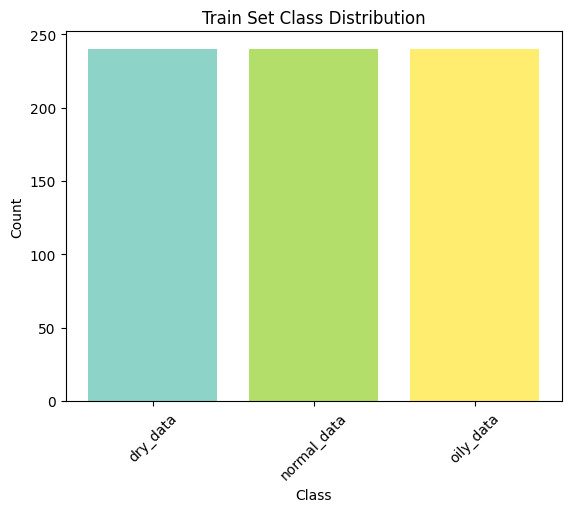

In [16]:
def visualize_class_distribution(generator, title):
    labels = generator.classes
    class_names = list(generator.class_indices.keys())
    class_counts = [labels.count(cls) for cls in range(len(class_names))]
    colors = plt.cm.Set3(np.linspace(0, 1, len(class_names)))

    plt.bar(class_names, class_counts, color=colors)
    plt.title(title)
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.show()

visualize_class_distribution(train_generator, 'Train Set Class Distribution')

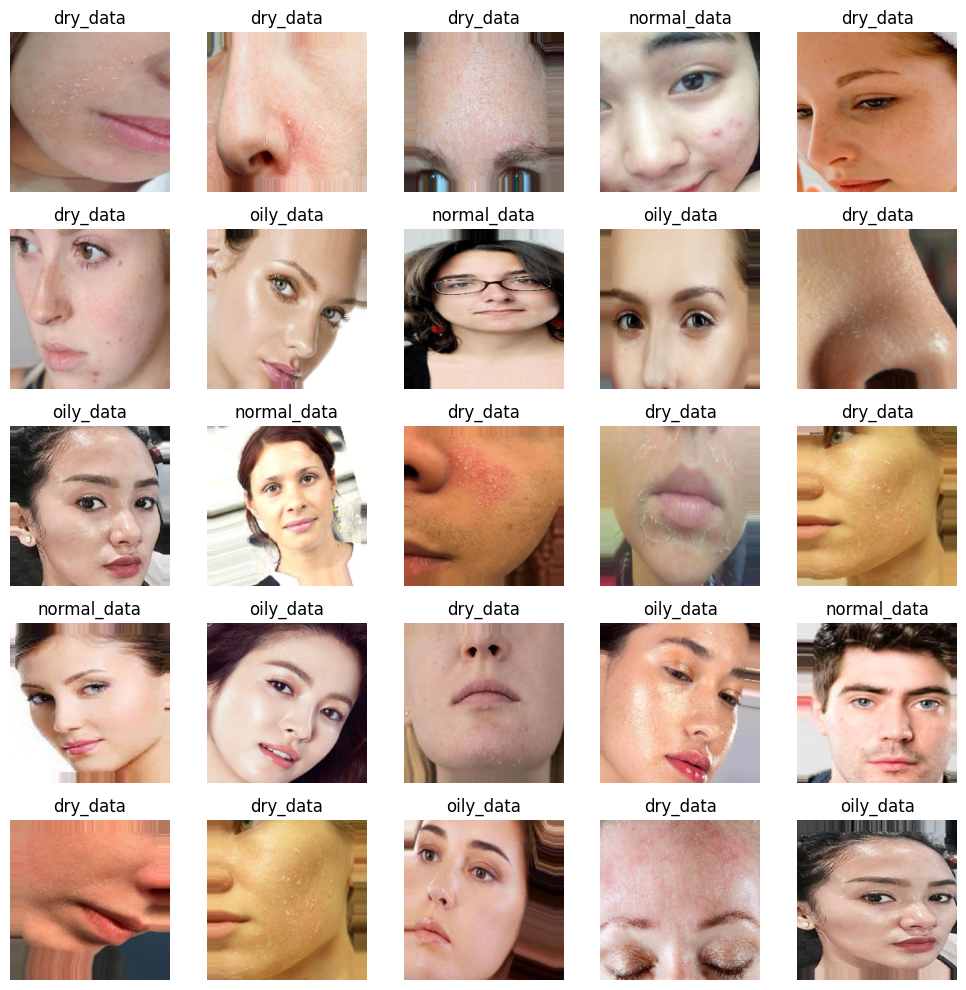

In [7]:
def display_images_with_labels(generator):
    fig, axes = plt.subplots(5, 5, figsize=(10, 10))
    axes = axes.ravel()

    classes = generator.class_indices
    classes = list(classes.keys())

    for i in range(25):
        images, labels = next(generator)
        image = images[0]
        label = labels[0]
        label_index = label.argmax()

        axes[i].imshow(image)
        axes[i].set_title(classes[label_index])
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# Display images with labels from the train set
display_images_with_labels(train_generator)


In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
import os

def augment_class_to_target(class_folder, target_count, save_dir):
    datagen = ImageDataGenerator(
        rotation_range=20,
        zoom_range=0.2,
        horizontal_flip=True,
        brightness_range=[0.8, 1.2],
        width_shift_range=0.1,
        height_shift_range=0.1,
        fill_mode='nearest'
    )
    
    # Filter only valid image files
    valid_ext = ('.jpg', '.jpeg', '.png', '.webp')
    images = [f for f in os.listdir(class_folder) if f.lower().endswith(valid_ext)]
    current_count = len(images)
    needed = target_count - current_count
    os.makedirs(save_dir, exist_ok=True)
    
    if needed <= 0:
        print(f"[SKIP] {os.path.basename(class_folder)} already has {current_count} images (target: {target_count})")
        return
    
    generated = 0
    while generated < needed:
        img_path = os.path.join(class_folder, images[generated % current_count])
        img = load_img(img_path)
        x = img_to_array(img)
        x = x.reshape((1,) + x.shape)
        
        for batch in datagen.flow(x, batch_size=1,
                                   save_to_dir=save_dir,
                                   save_prefix='aug',
                                   save_format='jpg'):
            generated += 1
            break
    
    print(f"[DONE] {os.path.basename(class_folder)}: {current_count} original + {generated} augmented = {current_count + generated} total")


def balance_all_classes(train_dir, target_count=300):
    """
    Automatically finds all class folders and augments each to target_count.
    """
    valid_ext = ('.jpg', '.jpeg', '.png', '.webp')
    
    # Auto-discover all class folders
    classes = [d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))]
    
    print("=" * 50)
    print("BEFORE AUGMENTATION")
    print("=" * 50)
    for cls in classes:
        folder = os.path.join(train_dir, cls)
        count = len([f for f in os.listdir(folder) if f.lower().endswith(valid_ext)])
        print(f"  {cls:<20} {count:>6} images")
    print("=" * 50)
    print(f"Augmenting all classes to {target_count} images...\n")

    # Augment each class
    for cls in classes:
        folder = os.path.join(train_dir, cls)
        augment_class_to_target(
            class_folder=folder,
            target_count=target_count,
            save_dir=folder  # saves into same folder
        )

    # Print final distribution
    print()
    print("=" * 50)
    print("AFTER AUGMENTATION")
    print("=" * 50)
    total = 0
    for cls in classes:
        folder = os.path.join(train_dir, cls)
        count = len([f for f in os.listdir(folder) if f.lower().endswith(valid_ext)])
        total += count
        print(f"  {cls:<20} {count:>6} images")
    print("-" * 50)
    print(f"  {'TOTAL':<20} {total:>6} images")
    print("=" * 50)


# ---- Run ----
train_dir = "E:/Realtime_skin_care_analyst/data/raw/skin_type/train"
balance_all_classes(train_dir, target_count=300)

BEFORE AUGMENTATION
  dry_data                300 images
  normal_data             300 images
  oily_data               300 images
Augmenting all classes to 300 images...

[SKIP] dry_data already has 300 images (target: 300)
[SKIP] normal_data already has 300 images (target: 300)
[SKIP] oily_data already has 300 images (target: 300)

AFTER AUGMENTATION
  dry_data                300 images
  normal_data             300 images
  oily_data               300 images
--------------------------------------------------
  TOTAL                   900 images


In [27]:
base_model = "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b0/feature_vector/2"

image_shape = (224, 224, 3)

def create_model(base_model, num_classes=3):
  try:
    # TensorFlow Hub can be incompatible with the Keras version in the active environment.
    feature_extractor_layer = hub.KerasLayer(
        base_model,
        trainable=False,
        name="efficientnet_v2_b0",
        input_shape=image_shape)
  except (TypeError, ValueError, ImportError) as error:
    print(f"TensorFlow Hub model unavailable; using local EfficientNetV2B0: {error}")
    feature_extractor_layer = tf.keras.applications.EfficientNetV2B0(
        include_top=False,
        weights="imagenet",
        pooling="avg",
        input_shape=image_shape)
    feature_extractor_layer.trainable = False

  try:
    model = tf.keras.Sequential([
      feature_extractor_layer,
      tf.keras.layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001),
      tf.keras.layers.Dense(64, kernel_regularizer=regularizers.l2(0.016), activity_regularizer=regularizers.l1(0.006),
                  bias_regularizer=regularizers.l1(0.006), activation='relu'),
      tf.keras.layers.Dropout(rate=0.45, seed=123),
      tf.keras.layers.Dense(num_classes, activation='softmax')
    ])
    return model
  except (TypeError, ValueError) as error:
    print(f"TensorFlow Hub layer incompatible; using local EfficientNetV2B0: {error}")
    feature_extractor_layer = tf.keras.applications.EfficientNetV2B0(
        include_top=False, weights='imagenet', pooling='avg', input_shape=image_shape)
    feature_extractor_layer.trainable = False
    return tf.keras.Sequential([
      feature_extractor_layer,
      tf.keras.layers.BatchNormalization(),
      tf.keras.layers.Dense(64, activation='relu'),
      tf.keras.layers.Dropout(0.45, seed=123),
      tf.keras.layers.Dense(num_classes, activation='softmax')
    ])

In [28]:
# Create model
model = create_model(base_model, num_classes=3)

# Compile
model.compile(loss="categorical_crossentropy",
              optimizer=Adamax(learning_rate= 0.001),
              metrics=['accuracy'])
model.summary()

TensorFlow Hub layer incompatible; using local EfficientNetV2B0: Only instances of `keras.Layer` can be added to a Sequential model. Received: <tensorflow_hub.keras_layer.KerasLayer object at 0x0000021A8834C2E0> (of type <class 'tensorflow_hub.keras_layer.KerasLayer'>)
24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetv2-b0 (Functional)  │ (None, 1280)           │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,006,611 (22.91 MB)

 Trainable params: 84,739 (331.01 KB)

 Non-trainable params: 5,921,872 (22.59 MB)

In [12]:
history = model.fit(train_generator, epochs=20,
                    validation_data=validation_generator, shuffle= False)

Epoch 1/20
18/18 [==============================] - 105s 5s/step - loss: 2.8708 - accuracy: 0.6778 - val_loss: 2.8154 - val_accuracy: 0.7222
Epoch 2/20
18/18 [==============================] - 66s 4s/step - loss: 2.4381 - accuracy: 0.8222 - val_loss: 2.4723 - val_accuracy: 0.8000
Epoch 3/20
18/18 [==============================] - 64s 4s/step - loss: 2.2327 - accuracy: 0.8847 - val_loss: 2.2596 - val_accuracy: 0.8333
Epoch 4/20
18/18 [==============================] - 63s 4s/step - loss: 2.1260 - accuracy: 0.8792 - val_loss: 2.1205 - val_accuracy: 0.8667
Epoch 5/20
18/18 [==============================] - 64s 4s/step - loss: 2.0343 - accuracy: 0.9042 - val_loss: 2.0140 - val_accuracy: 0.8667
Epoch 6/20
18/18 [==============================] - 67s 4s/step - loss: 1.9153 - accuracy: 0.9181 - val_loss: 1.9210 - val_accuracy: 0.8833
Epoch 7/20
18/18 [==============================] - 61s 3s/step - loss: 1.8473 - accuracy: 0.9181 - val_loss: 1.8424 - val_accuracy: 0.8889
Epoch 8/20
18/18 [=

In [13]:
ts_length = len(test_df)
test_batch_size = test_batch_size = max(sorted([ts_length // n for n in range(1, ts_length + 1) if ts_length%n == 0 and ts_length/n <= 80]))
test_steps = ts_length // test_batch_size

train_score = model.evaluate(train_generator, steps= test_steps, verbose= 1)
valid_score = model.evaluate(validation_generator, steps= test_steps, verbose= 1)
test_score = model.evaluate(test_generator, steps= test_steps, verbose= 1)

print("Train Loss: ", train_score[0])
print("Train Accuracy: ", train_score[1])
print('-' * 20)
print("Validation Loss: ", valid_score[0])
print("Validation Accuracy: ", valid_score[1])
print('-' * 20)
print("Test Loss: ", test_score[0])
print("Test Accuracy: ", test_score[1])

2/2 [==============================] - 6s 3s/step - loss: 1.0862 - accuracy: 0.9875
Train Loss:  1.0645755529403687
Train Accuracy:  0.987500011920929
--------------------
Validation Loss:  1.1352880001068115
Validation Accuracy:  0.9624999761581421
--------------------
Test Loss:  1.0861884355545044
Test Accuracy:  0.987500011920929


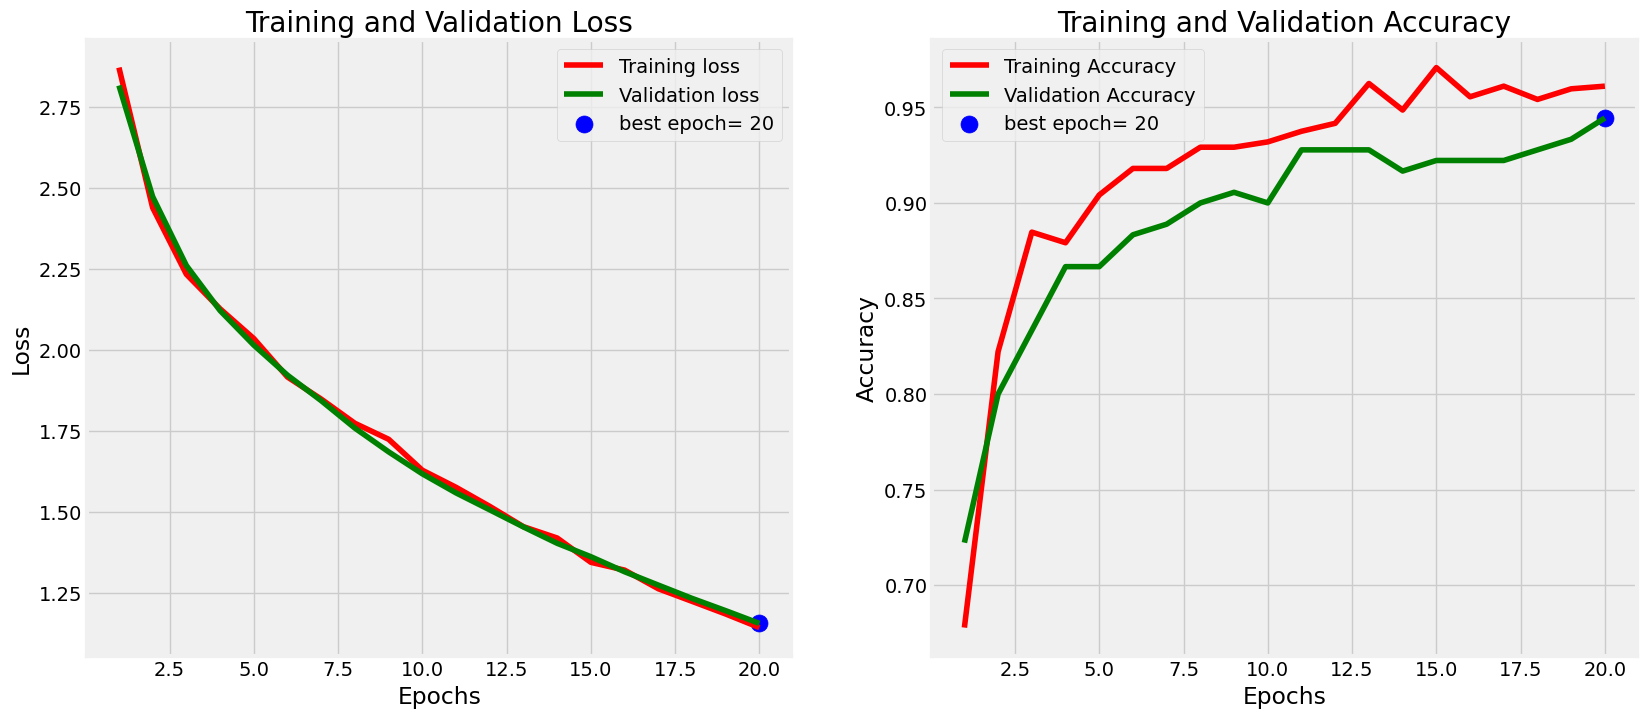

In [14]:
def plot_training(hist):
    '''
    This function take training model and plot history of accuracy and losses with the best epoch in both of them.
    '''

    # Define needed variables
    tr_acc = hist.history['accuracy']
    tr_loss = hist.history['loss']
    val_acc = hist.history['val_accuracy']
    val_loss = hist.history['val_loss']
    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]
    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]
    Epochs = [i+1 for i in range(len(tr_acc))]
    loss_label = f'best epoch= {str(index_loss + 1)}'
    acc_label = f'best epoch= {str(index_acc + 1)}'

    # Plot training history
    plt.figure(figsize= (20, 8))
    plt.style.use('fivethirtyeight')

    plt.subplot(1, 2, 1)
    plt.plot(Epochs, tr_loss, 'r', label= 'Training loss')
    plt.plot(Epochs, val_loss, 'g', label= 'Validation loss')
    plt.scatter(index_loss + 1, val_lowest, s= 150, c= 'blue', label= loss_label)
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(Epochs, tr_acc, 'r', label= 'Training Accuracy')
    plt.plot(Epochs, val_acc, 'g', label= 'Validation Accuracy')
    plt.scatter(index_acc + 1 , acc_highest, s= 150, c= 'blue', label= acc_label)
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout
    plt.show()

plot_training(history)

In [8]:
def plot_confusion_matrix(cm, classes, normalize= False, title= 'Confusion Matrix', cmap= plt.cm.Blues):
	'''
	This function plot confusion matrix method from sklearn package.
	'''

	plt.figure(figsize= (10, 10))
	plt.imshow(cm, interpolation= 'nearest', cmap= cmap)
	plt.title(title)
	plt.colorbar()

	tick_marks = np.arange(len(classes))
	plt.xticks(tick_marks, classes, rotation= 45)
	plt.yticks(tick_marks, classes)

	if normalize:
		cm = cm.astype('float') / cm.sum(axis= 1)[:, np.newaxis]
		print('Normalized Confusion Matrix')

	else:
		print('Confusion Matrix, Without Normalization')

	print(cm)

	thresh = cm.max() / 2.
	for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
		plt.text(j, i, cm[i, j], horizontalalignment= 'center', color= 'white' if cm[i, j] > thresh else 'black')

	plt.tight_layout()
	plt.ylabel('True Label')
	plt.xlabel('Predicted Label')

In [9]:
preds = model.predict_generator(test_generator)
y_pred = np.argmax(preds, axis=1)
print(y_pred)

C:\Users\Dell\AppData\Local\Temp\ipykernel_3228\4068590537.py:1: UserWarning: `Model.predict_generator` is deprecated and will be removed in a future version. Please use `Model.predict`, which supports generators.
  preds = model.predict_generator(test_generator)


[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


Confusion Matrix, Without Normalization
[[ 0 42  0]
 [ 0 45  1]
 [ 0 40  0]]


C:\Users\Dell\AppData\Roaming\Python\Python310\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Dell\AppData\Roaming\Python\Python310\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Dell\AppData\Roaming\Python\Python310\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

              precision    recall  f1-score   support

    dry_data       0.00      0.00      0.00        42
 normal_data       0.35      0.98      0.52        46
   oily_data       0.00      0.00      0.00        40

    accuracy                           0.35       128
   macro avg       0.12      0.33      0.17       128
weighted avg       0.13      0.35      0.19       128



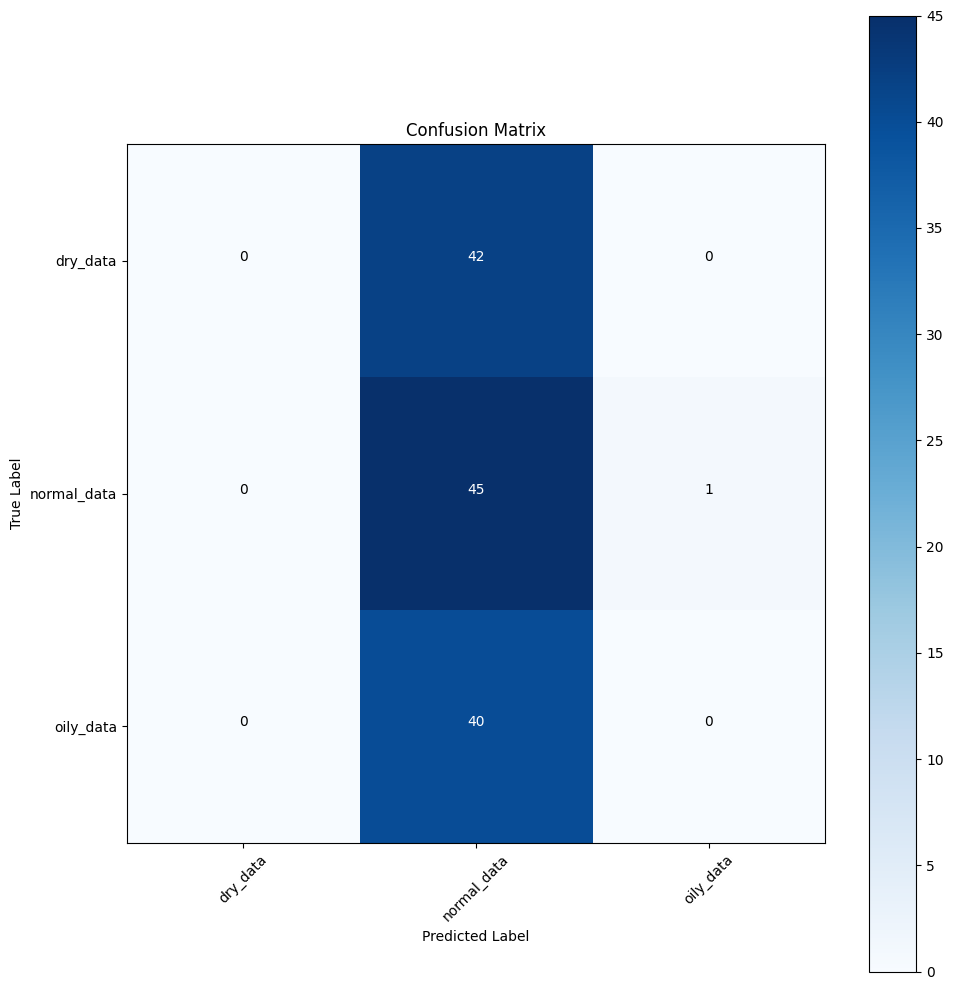

In [10]:
g_dict = test_generator.class_indices
classes = list(g_dict.keys())

# Confusion matrix
cm = confusion_matrix(test_generator.classes, y_pred)
plot_confusion_matrix(cm= cm, classes= classes, title = 'Confusion Matrix')

# Classification report
print(classification_report(test_generator.classes, y_pred, target_names= classes))
     

In [29]:
# Save the trained model
import os
import pickle

# Create model directory if it doesn't exist
model_dir = 'model'
os.makedirs(model_dir, exist_ok=True)

# Reuse an existing artifact when the training cell was not run successfully.
model_path = os.path.join(model_dir, 'skin_type_classification_model.h5')
if 'model' not in globals():
    if not os.path.exists(model_path):
        raise RuntimeError(
            "No model is available. Run the model creation and training cells first."
        )
    from tensorflow.keras.models import load_model
    model = load_model(model_path, custom_objects={'KerasLayer': hub.KerasLayer})
    print(f"Using existing model at: {model_path}")

try:
    model.save(model_path)
    print(f"Model saved successfully at: {model_path}")
    
    # Get class labels - try from generators first, fallback to unique labels from data
    try:
        if 'train_generator' in globals() and hasattr(train_generator, 'class_indices'):
            classes = list(train_generator.class_indices.keys())
            print(f"Classes obtained from train_generator: {classes}")
        else:
            # Fallback: get unique classes from the dataframes
            all_labels = set()
            if len(train_df) > 0:
                all_labels.update(train_df['labels'].unique())
            if len(test_df) > 0:
                all_labels.update(test_df['labels'].unique())
            classes = sorted(list(all_labels))
            print(f"Classes obtained from dataframes: {classes}")
            
            if not classes:
                classes = ['dry_data', 'normal_data', 'oily_data']  # Default classes
                print(f"Using default classes: {classes}")
    
    except Exception as e:
        print(f"Error getting classes: {e}")
        classes = ['dry_data', 'normal_data', 'oily_data']  # Default fallback
        print(f"Using fallback classes: {classes}")
    
    # Save class labels for later use
    classes_path = os.path.join(model_dir, 'class_labels.pkl')
    with open(classes_path, 'wb') as f:
        pickle.dump(classes, f)
    print(f"Class labels saved at: {classes_path}")
    print(f"Classes: {classes}")
    
except Exception as e:
    print(f"Error saving model: {e}")

Model saved successfully at: model\skin_type_classification_model.h5
Classes obtained from train_generator: ['dry_data', 'normal_data', 'oily_data']
Class labels saved at: model\class_labels.pkl
Classes: ['dry_data', 'normal_data', 'oily_data']


In [30]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import clear_output, display, Image as IPImage
import time
import numpy as np
from matplotlib.patches import Rectangle
from tensorflow.keras.models import load_model
import tensorflow_hub as hub
import pickle

In [37]:
# Load the saved model and class labels
def load_trained_model():
    """Load the trained model and class labels"""
    try:
        # Load the model with custom objects
        import tensorflow_hub as hub
        model_path = os.path.join('model', 'skin_type_classification_model.h5')
        loaded_model = load_model(model_path, custom_objects={'KerasLayer': hub.KerasLayer})
        print("Model loaded successfully!")
        
        # Load class labels
        classes_path = os.path.join('model', 'class_labels.pkl')
        with open(classes_path, 'rb') as f:
            class_labels = pickle.load(f)
        print(f"Class labels loaded: {class_labels}")
        
        return loaded_model, class_labels
    except Exception as e:
        raise RuntimeError(
            f"Unable to load the skin type model from {model_path}. "
            "Run the model creation/training cell or repair the saved model artifact."
        ) from e

# Load the model (using the current trained model for now)
loaded_model, class_labels = load_trained_model()
if loaded_model is None or not hasattr(loaded_model, 'predict'):
    raise RuntimeError("The loaded skin type model is invalid or unavailable.")

Model loaded successfully!
Class labels loaded: ['dry_data', 'normal_data', 'oily_data']


In [38]:
# Image preprocessing function
def preprocess_image(img, target_size=(224, 224)):
    """
    Preprocess image for model prediction
    """
    # Resize image
    img_resized = cv2.resize(img, target_size)
    
    # Convert BGR to RGB (OpenCV uses BGR, model expects RGB)
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Normalize pixel values to [0, 1]
    img_normalized = img_rgb.astype(np.float32) / 255.0
    
    # Add batch dimension
    img_batch = np.expand_dims(img_normalized, axis=0)
    
    return img_batch

# Skin type prediction function
def predict_skin_type(model, img, class_labels):
    """
    Predict skin type from image
    """
    if model is None or not hasattr(model, 'predict'):
        raise ValueError(
            "A trained skin type model is required. Run the model-loading cell first."
        )
    if not class_labels:
        raise ValueError("Class labels are required for skin type prediction.")

    # Preprocess image
    processed_img = preprocess_image(img)
    
    # Make prediction
    predictions = model.predict(processed_img, verbose=0)
    predicted_class_idx = np.argmax(predictions[0])
    confidence = predictions[0][predicted_class_idx]
    predicted_class = class_labels[predicted_class_idx]
    
    return predicted_class, confidence, predictions[0]

In [39]:
# Face detection setup
def setup_face_detection():
    """
    Setup face detection using OpenCV's Haar cascades
    """
    try:
        # Load face detection classifier
        face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
        print("Face detection classifier loaded successfully!")
        return face_cascade
    except Exception as e:
        print(f"Error loading face classifier: {e}")
        return None

# Initialize face detection
face_cascade = setup_face_detection()

def detect_faces(img, face_cascade):
    """
    Detect faces in image
    """
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(50, 50))
    return faces

def extract_face_region(img, face_coords, padding=20):
    """
    Extract face region with padding
    """
    x, y, w, h = face_coords
    # Add padding
    x_start = max(0, x - padding)
    y_start = max(0, y - padding)
    x_end = min(img.shape[1], x + w + padding)
    y_end = min(img.shape[0], y + h + padding)
    
    face_img = img[y_start:y_end, x_start:x_end]
    return face_img, (x_start, y_start, x_end - x_start, y_end - y_start)

Face detection classifier loaded successfully!


In [40]:
import cv2
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time

def analyze_skin_from_video(model, class_labels, face_cascade, duration=30, notebook=True):
    """
    Capture video and analyze skin type in real-time
    Args:
        model: Trained skin classification model
        class_labels: List of class labels
        face_cascade: Face detection classifier
        duration: Duration to run analysis (seconds)
        notebook: If True, uses matplotlib inline (for Jupyter/Colab). 
                  If False, uses OpenCV windows (desktop only).
    """
    if model is None or not hasattr(model, 'predict'):
        raise ValueError(
            "A trained skin type model is required. Run the model-loading cell first."
        )
    if face_cascade is None:
        raise ValueError("A face detection classifier is required.")
    if not class_labels:
        raise ValueError("Class labels are required for video analysis.")
    cap = cv2.VideoCapture(0)  # Default camera
    
    if not cap.isOpened():
        print("Error: Could not open camera")
        return []
    
    print("Starting skin analysis. Press 'q' to quit (only works in desktop mode).")
    print("Make sure your face is well-lit and centered in the frame")
    
    frame_count = 0
    analysis_results = []
    start_time = time.time()
    
    while True:
        ret, frame = cap.read()
        if not ret:
            print("Error: Could not read frame")
            break
        
        # Flip frame for mirror effect
        frame = cv2.flip(frame, 1)
        
        # Detect faces
        faces = detect_faces(frame, face_cascade)
        
        for (x, y, w, h) in faces:
            cv2.rectangle(frame, (x, y), (x+w, y+h), (255, 0, 0), 2)
            
            face_img, _ = extract_face_region(frame, (x, y, w, h))
            if face_img.size > 0:
                predicted_class, confidence, all_predictions = predict_skin_type(
                    model, face_img, class_labels
                )
                
                result_text = f"Skin Type: {predicted_class}"
                confidence_text = f"Conf: {confidence:.2f}"
                
                cv2.putText(frame, result_text, (x, y-30), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
                cv2.putText(frame, confidence_text, (x, y-10), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
                
                for i, (class_name, prob) in enumerate(zip(class_labels, all_predictions)):
                    prob_text = f"{class_name}: {prob:.3f}"
                    cv2.putText(frame, prob_text, (10, 30 + i*20), 
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
        
        # --- Display frame ---
        if notebook:
            clear_output(wait=True)
            plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            plt.axis("off")
            display(plt.gcf())
        else:
            cv2.imshow("Skin Type Analysis", frame)
            key = cv2.waitKey(1) & 0xFF
            if key == ord('q'):
                break
        
        frame_count += 1
        if time.time() - start_time > duration:
            break
    
    cap.release()
    if not notebook:
        cv2.destroyAllWindows()
    
    return analysis_results

In [41]:
def test_with_static_image(model, class_labels, face_cascade, image_path, show_image=True):
    """
    Test the skin analysis with a static image
    """
    # Read image
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: Could not load image from {image_path}")
        return
    
    # Resize image if too large for better display
    original_height, original_width = img.shape[:2]
    max_width = 800
    if original_width > max_width:
        scale = max_width / original_width
        new_width = int(original_width * scale)
        new_height = int(original_height * scale)
        img = cv2.resize(img, (new_width, new_height))
        print(f"Image resized from {original_width}x{original_height} to {new_width}x{new_height}")
    
    # Detect faces
    faces = detect_faces(img, face_cascade)
    
    if len(faces) == 0:
        print("No faces detected in the image")
        return
    
    print(f"Detected {len(faces)} face(s)")
    
    # Analyze each face
    for i, (x, y, w, h) in enumerate(faces):
        # Draw thicker rectangle around face for better visibility
        cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 3)
        
        # Extract face region
        face_img, _ = extract_face_region(img, (x, y, w, h))
        
        if face_img.size > 0:
            # Predict skin type
            predicted_class, confidence, all_predictions = predict_skin_type(
                model, face_img, class_labels
            )
            
            # Print results once
            print(f"\nFace {i+1}:")
            print(f"  Predicted skin type: {predicted_class}")
            print(f"  Confidence: {confidence:.3f}")
            print("  All predictions:")
            for class_name, prob in zip(class_labels, all_predictions):
                print(f"    {class_name}: {prob:.3f}")
            
            # Improved text rendering with better visibility
            result_text = f"{predicted_class} ({confidence:.2f})"
            
            # Calculate dynamic font size based on image size
            font_scale = max(0.6, min(1.2, img.shape[1] / 800))
            thickness = max(2, int(font_scale * 2))
            
            # Get text size to create background
            (text_width, text_height), baseline = cv2.getTextSize(
                result_text, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness
            )
            
            # Create background rectangle for better text visibility
            text_x = x
            text_y = y - 15
            
            # Draw text in bright green
            cv2.putText(img, result_text, (text_x, text_y), 
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 255, 0), thickness)
    
    # Display result with optimized size
    if show_image:
        # Calculate optimal figure size based on image dimensions
        img_height, img_width = img.shape[:2]
        aspect_ratio = img_width / img_height
        
        # Set maximum display width to 10 inches, adjust height accordingly
        max_display_width = 10
        fig_width = min(max_display_width, aspect_ratio * 6)
        fig_height = fig_width / aspect_ratio
        
        plt.figure(figsize=(fig_width, fig_height))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title('Skin Type Analysis Results', fontsize=14, fontweight='bold')
        plt.axis('off')
        
        # Adjust layout to remove extra whitespace
        plt.tight_layout()
        plt.subplots_adjust(left=0, right=1, top=0.95, bottom=0)
        plt.show()

Testing with sample image...
Image resized from 2560x1707 to 800x533
Detected 1 face(s)

Face 1:
  Predicted skin type: dry_data
  Confidence: 0.419
  All predictions:
    dry_data: 0.419
    normal_data: 0.336
    oily_data: 0.245


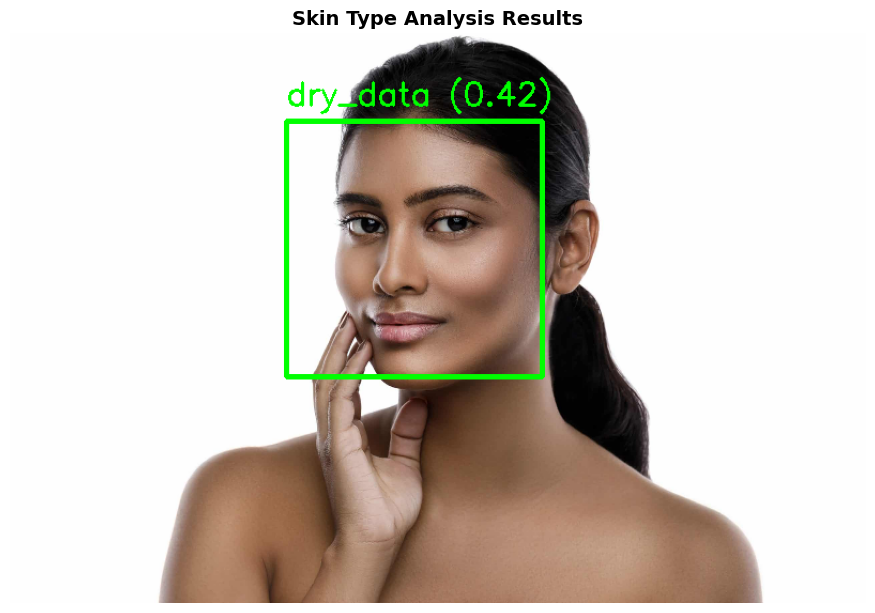

In [44]:
# Test with a sample image from the dataset
sample_image_path = r"E:/Realtime_skin_care_analyst/even-skin-tone-scaled.jpeg"

print("Testing with sample image...")
if os.path.exists(sample_image_path):
    test_result = test_with_static_image(loaded_model, class_labels, face_cascade, sample_image_path)
else:
    print(f"Sample image not found at: {sample_image_path}")
    print("Available test images:")
    test_dir = r"data\raw\skin_types\test"
    if os.path.exists(test_dir):
        for skin_type in os.listdir(test_dir):
            skin_type_path = os.path.join(test_dir, skin_type)
            if os.path.isdir(skin_type_path):
                images = os.listdir(skin_type_path)[:3]  # Show first 3 images
                print(f"  {skin_type}: {images}")

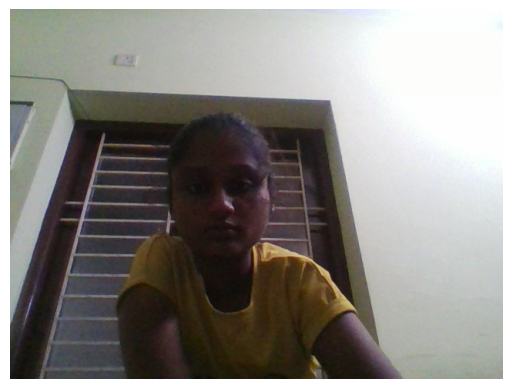

KeyboardInterrupt: 

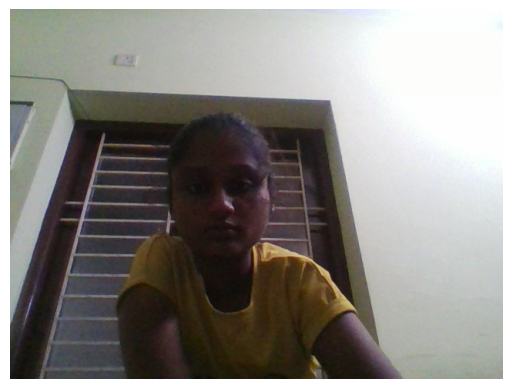

In [43]:
# Main execution cell for real-time video analysis
# WARNING: This will open your camera and start real-time analysis
# Make sure your camera is connected and working

print("="*50)
print("REAL-TIME SKIN TYPE ANALYSIS")
print("="*50)
print("Instructions:")
print("1. Make sure your camera is connected and working")
print("2. Position your face in front of the camera")
print("3. Ensure good lighting for better results")
print("4. Press 'q' to quit the analysis")
print("5. Press 's' to save current frame analysis")
print("="*50)

results = analyze_skin_from_video(loaded_model, class_labels, face_cascade, duration=60, notebook=True)

print("To start real-time analysis, run the cell above")
print("The analysis will show:")
print("- Real-time skin type prediction")
print("- Confidence scores")
print("- Bounding boxes around detected faces")
print("- All class probabilities in real-time")

In [44]:
'''# Batch processing function for multiple images
def batch_analyze_images(model, class_labels, face_cascade, image_folder, max_images=5):
    """
    Analyze multiple images from a folder
    """
    if not os.path.exists(image_folder):
        print(f"Folder not found: {image_folder}")
        return
    
    image_files = [f for f in os.listdir(image_folder) 
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    if not image_files:
        print(f"No image files found in {image_folder}")
        return
    
    # Limit number of images to process
    image_files = image_files[:max_images]
    
    results = []
    
    for i, image_file in enumerate(image_files):
        image_path = os.path.join(image_folder, image_file)
        print(f"\nProcessing image {i+1}/{len(image_files)}: {image_file}")
        
        # Read image
        img = cv2.imread(image_path)
        if img is None:
            print(f"Could not load image: {image_file}")
            continue
        
        # Detect faces
        faces = detect_faces(img, face_cascade)
        
        if len(faces) == 0:
            print(f"No faces detected in {image_file}")
            continue
        
        # Analyze each face
        image_results = []
        for j, (x, y, w, h) in enumerate(faces):
            face_img, _ = extract_face_region(img, (x, y, w, h))
            
            if face_img.size > 0:
                predicted_class, confidence, all_predictions = predict_skin_type(
                    model, face_img, class_labels
                )
                
                face_result = {
                    'image_file': image_file,
                    'face_id': j,
                    'predicted_class': predicted_class,
                    'confidence': confidence,
                    'all_predictions': dict(zip(class_labels, all_predictions))
                }
                image_results.append(face_result)
                
                print(f"  Face {j+1}: {predicted_class} (confidence: {confidence:.3f})")
        
        results.extend(image_results)
    
    return results

# Test with a few images from each skin type
print("Testing batch processing with sample images from each skin type:")

test_folders = [
    (r"E:\skin_care\data\raw\skin_type\validation\dry_data", "dry"),
    (r"E:\skin_care\data\raw\skin_type\validation\normal_data", "normal"), 
    (r"E:\skin_care\data\raw\skin_type\validation\oily_data", "oily")
]

all_batch_results = []
for folder_path, true_label in test_folders:
    print(f"\n{'='*20} Testing {true_label.upper()} skin type images {'='*20}")
    batch_results = batch_analyze_images(loaded_model, class_labels, face_cascade, folder_path, max_images=3)
    
    if batch_results:
        all_batch_results.extend(batch_results)
        
        # Calculate accuracy for this skin type
        correct_predictions = sum(1 for result in batch_results if result['predicted_class'] == true_label)
        accuracy = correct_predictions / len(batch_results) if batch_results else 0
        print(f"\nAccuracy for {true_label} images: {accuracy:.2f} ({correct_predictions}/{len(batch_results)})")
'''


'# Batch processing function for multiple images\ndef batch_analyze_images(model, class_labels, face_cascade, image_folder, max_images=5):\n    """\n    Analyze multiple images from a folder\n    """\n    if not os.path.exists(image_folder):\n        print(f"Folder not found: {image_folder}")\n        return\n    \n    image_files = [f for f in os.listdir(image_folder) \n                   if f.lower().endswith((\'.jpg\', \'.jpeg\', \'.png\'))]\n    \n    if not image_files:\n        print(f"No image files found in {image_folder}")\n        return\n    \n    # Limit number of images to process\n    image_files = image_files[:max_images]\n    \n    results = []\n    \n    for i, image_file in enumerate(image_files):\n        image_path = os.path.join(image_folder, image_file)\n        print(f"\nProcessing image {i+1}/{len(image_files)}: {image_file}")\n        \n        # Read image\n        img = cv2.imread(image_path)\n        if img is None:\n            print(f"Could not load image: